# Teaching a policy to play a real MOBA inside a learned world model: figures

Every figure of the paper, generated from `results/moba/paper/` (built by `scripts/moba/paper_data.py`) and saved to
`docs/moba/paper/figures/`. Nothing here is typed in by hand: re-run the data script after a new evaluation and
re-execute this notebook.

**Reading the numbers.** A *win rate* is only ever measured on the **holdout** seeds (70000000+) or **holdout2**
(80000000+), which no choice was ever made on. The fixed 60-seed curves are training signals, not results.
See `docs/moba/EVALUATION.md`.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "results/moba/paper").exists():
    ROOT = ROOT.parent
P, FIG = ROOT / "results/moba/paper", ROOT / "docs/moba/paper/figures"
FIG.mkdir(parents=True, exist_ok=True)
N = json.loads((P / "numbers.json").read_text())
read = lambda f: pd.read_csv(P / f) if (P / f).exists() else pd.DataFrame()
online, dream, wm, wmt, dyt, col, drift = (read(f) for f in
    ("online_fixed.csv", "dream.csv", "wm_train.csv", "wm_tower.csv", "dyna_tower.csv", "collector.csv", "drift.csv"))
ev = [json.loads(l) for l in (P / "seed_evals.jsonl").read_text().splitlines() if l.strip()]
ev = list({(r["label"], r["set"]): r for r in ev}.values())             # the latest row per (policy, seed set)

# Okabe-Ito (colorblind-safe), one meaning per color across every figure
C = dict(ours="#0072B2", ours2="#56B4E9", bad="#D55E00", bad2="#E69F00", net="#555555", rand="#BBBBBB",
         dyna="#009E73", e38="#CC79A7", dire="#D55E00")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "legend.frameon": False, "figure.constrained_layout.use": True})

def wilson(k, n, z=1.96):
    if n == 0: return np.nan, np.nan, np.nan
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return p, min(c - h, p), max(c + h, p)                              # clamp float rounding at 0% / 100%

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white"); plt.show()

print("headline:", json.dumps(N.get("headline"), indent=1))

headline: {
 "policy": "ppol4_u69",
 "set": "holdout",
 "radiant_wins": 213,
 "radiant_games": 300,
 "radiant_rate": 0.71,
 "radiant_ci95": [
  0.6562534723961281,
  0.7584362870048228
 ],
 "dire_wins": 0,
 "dire_games": 300,
 "dire_ci95": [
  0.0,
  0.012643429997735661
 ],
 "pooled_untouched": {
  "radiant_wins": 421,
  "radiant_games": 600,
  "rate": 0.7016666666666667,
  "ci95": [
   0.6638680212177496,
   0.7368993323398721
  ]
 }
}


## Figure 1. Real-game win rate against the shipped net (holdout seeds, 300 games per side)

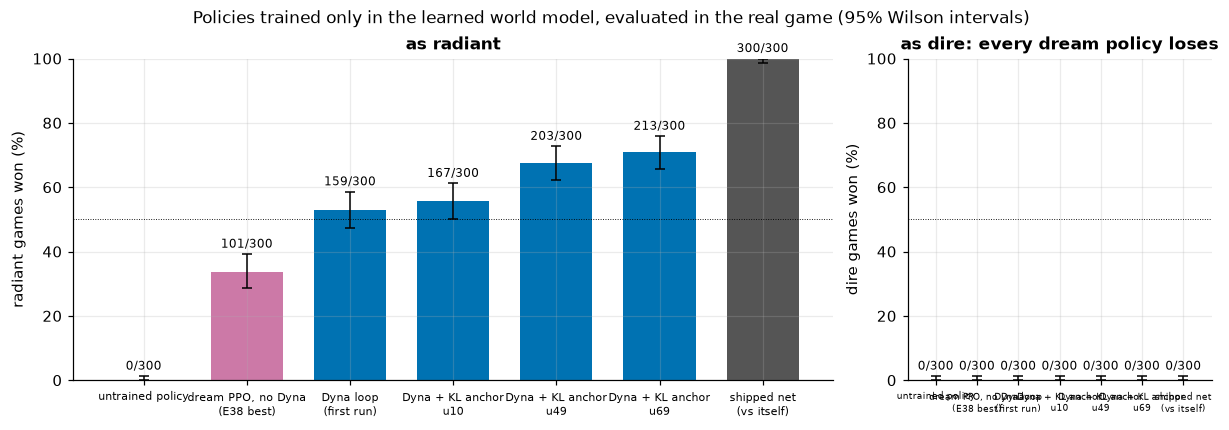

,label,set,radiant_wins,radiant_games,dire_wins,dire_games,radiant_towers_ours,radiant_kills,radiant_deaths,radiant_ticks,dire_ticks
13,E40_fz_dyna_u40,holdout,168,300,0,300,3.530,1.329,5.566,5593.897,1113.557
14,E40_fz_dynas1_u40,holdout,181,300,0,300,3.735,1.421,5.567,5587.383,1131.330
11,E40_fz_e38_u40,holdout,153,300,0,300,3.155,0.993,5.301,5602.030,1383.847
12,E40_fz_e38s1_u40,holdout,141,300,0,300,3.305,1.097,5.675,5662.687,1388.003
8,e14_armC,holdout,0,300,0,300,1.650,0.149,2.402,6000.000,1083.000
9,e36_J_envs128_4x_s2,holdout,4,300,0,300,2.875,0.877,6.079,5992.600,1078.060
10,e37_pf1_u7,holdout,17,300,0,300,3.025,1.571,5.014,5984.363,2922.103
1,e38_u0017,holdout,101,300,0,300,3.370,1.247,5.991,5743.670,1229.647
3,ppol4_u10,holdout,167,300,0,300,3.860,1.543,5.905,5629.643,1262.847
4,ppol4_u49,holdout,203,300,0,300,3.905,1.577,6.274,5485.627,1269.983


In [2]:
order = ["random", "e38_u0017", "ppol_u71", "ppol4_u10", "ppol4_u49", "ppol4_u69", "shipped_net"]
names = {"random": "untrained policy", "e38_u0017": "dream PPO, no Dyna\n(E38 best)", "ppol_u71": "Dyna loop\n(first run)",
         "ppol4_u10": "Dyna + KL anchor\nu10", "ppol4_u49": "Dyna + KL anchor\nu49", "ppol4_u69": "Dyna + KL anchor\nu69",
         "shipped_net": "shipped net\n(vs itself)"}
hold = {r["label"]: r for r in ev if r["set"] == "holdout"}
rows = [hold[l] for l in order if l in hold]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw=dict(width_ratios=[3, 1.2]))
for ax, side in zip(axs, ("radiant", "dire")):
    x = np.arange(len(rows))
    for i, r in enumerate(rows):
        p, lo, hi = wilson(r[f"{side}_wins"], r[f"{side}_games"])
        col_ = C["net"] if r["team"] == "net" else C["rand"] if r["team"] == "random" else C["e38"] if r["label"] == "e38_u0017" else C["ours"]
        ax.bar(i, 100*p, color=col_, width=0.7)
        ax.errorbar(i, 100*p, yerr=[[100*(p-lo)], [100*(hi-p)]], color="black", capsize=3, lw=1)
        ax.text(i, 100*hi + 2, f"{r[f'{side}_wins']}/{r[f'{side}_games']}", ha="center", fontsize=8)
    ax.set_xticks(x, [names.get(r["label"], r["label"]) for r in rows], fontsize=7.5)
    ax.set_ylim(0, 100); ax.set_ylabel(f"{side} games won (%)")
    ax.set_title(f"as {side}" + ("" if side == "radiant" else ": every dream policy loses"))
    ax.axhline(50, color="black", lw=0.6, ls=":")
axs[1].tick_params(axis="x", labelsize=6)
fig.suptitle("Policies trained only in the learned world model, evaluated in the real game (95% Wilson intervals)", fontsize=11)
save(fig, "fig1_holdout_winrate")
pd.DataFrame([{**{k: r[k] for k in ("label", "set", "radiant_wins", "radiant_games", "dire_wins", "dire_games",
               "radiant_towers_ours", "radiant_kills", "radiant_deaths", "radiant_ticks", "dire_ticks")}} for r in ev]).sort_values(["set", "label"])

## Figure 2. Online learning curves: dream PPO collapses in the real game unless it is anchored
Real radiant wins out of 60 (the fixed seeds) after every PPO update. Grey verticals: drift resets; green: a new
anchor (confirmed on 300 fresh games).

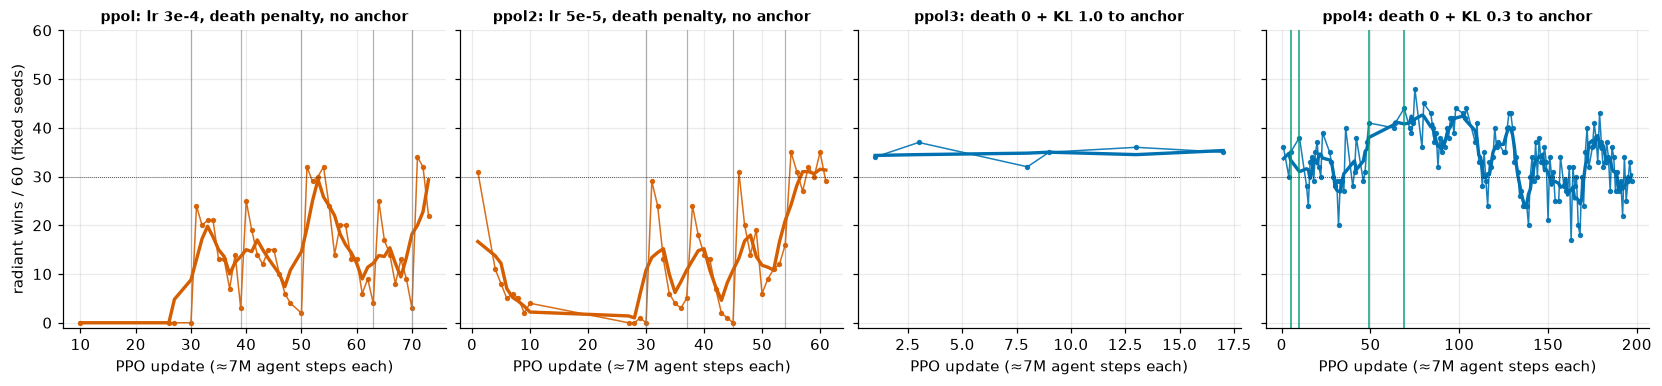

In [3]:
runs = [("ppol", "lr 3e-4, death penalty, no anchor"), ("ppol2", "lr 5e-5, death penalty, no anchor"),
        ("ppol3", "death 0 + KL 1.0 to anchor"), ("ppol4", "death 0 + KL 0.3 to anchor")]
state = json.loads((ROOT / "results/moba/dream/dyna_live_state.json").read_text())
fresh4 = [json.loads(l) for l in (ROOT / "results/moba/dream/ppol4_fresh.jsonl").read_text().splitlines() if l.strip()]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (run, lab) in zip(axs, runs):
    d = online[(online.run == run) & (online["update"] > 0)].sort_values("update")
    colr = C["bad"] if run in ("ppol", "ppol2") else C["ours"]
    ax.plot(d["update"], d.radiant_wins, "o-", ms=2.5, lw=1, color=colr, alpha=0.9)
    if len(d) > 4:
        ax.plot(d["update"], d.radiant_wins.rolling(5, min_periods=1, center=True).mean(), lw=2.2, color=colr)
    for r in state.get({"ppol": "resets_ppol", "ppol2": "resets_ppol2"}.get(run, "_none"), []):
        ax.axvline(r["at"], color="grey", lw=0.8, alpha=0.6)
    if run == "ppol4":
        for r in fresh4:
            if r["radiant_wins"] >= r["anchor_fresh"] + 9:
                ax.axvline(r["update"], color=C["dyna"], lw=1.2, alpha=0.8)
    ax.set_title(f"{run}: {lab}", fontsize=9); ax.set_xlabel("PPO update (≈7M agent steps each)")
    ax.axhline(30, color="black", lw=0.5, ls=":")
axs[0].set_ylabel("radiant wins / 60 (fixed seeds)"); axs[0].set_ylim(-1, 60)
save(fig, "fig2_online_curves")

## Figure 3. The collector's real games: thousands of games of the current policy, as it trains
Every game the Dyna collector played (to train the world model) is also an unbiased sample of the current policy's
real performance on new seeds. Binned by policy update, 95% Wilson intervals.

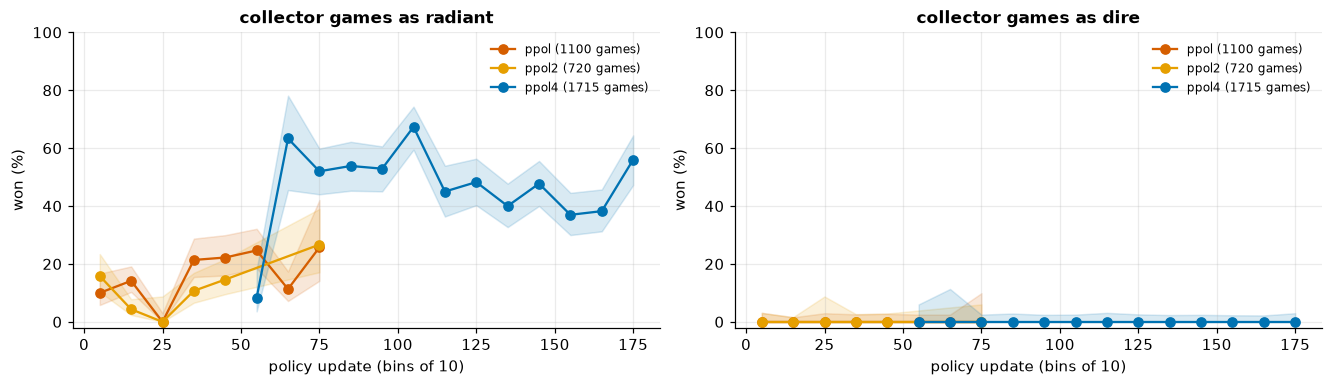

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, side in zip(axs, ("radiant", "dire")):
    for run, colr in (("ppol", C["bad"]), ("ppol2", C["bad2"]), ("ppol4", C["ours"])):
        d = col[(col.run == run) & (col.our_side == side)]
        if d.empty: continue
        d = d.assign(bin=(d.policy_update // 10) * 10 + 5)
        g = d.groupby("bin").agg(k=("won", "sum"), n=("won", "size")).reset_index()
        w = np.array([wilson(k, n) for k, n in zip(g.k, g.n)])
        ax.plot(g.bin, 100*w[:, 0], "o-", color=colr, label=f"{run} ({int(g.n.sum())} games)")
        ax.fill_between(g.bin, 100*w[:, 1], 100*w[:, 2], color=colr, alpha=0.15)
    ax.set_title(f"collector games as {side}"); ax.set_xlabel("policy update (bins of 10)"); ax.set_ylabel("won (%)")
    ax.set_ylim(-2, 100); ax.legend(fontsize=8)
save(fig, "fig3_collector_stream")

## Figure 4. Why the unanchored runs collapse: the dream cannot see it, the real game can
ppol2, updates 27-55. Left: correlation of each **dream** metric with real wins (none useful). Right: real-game
behaviour of the same policies: as wins fall, the heroes stop fighting (fewer kills *and* fewer deaths) and games
run to the time limit.

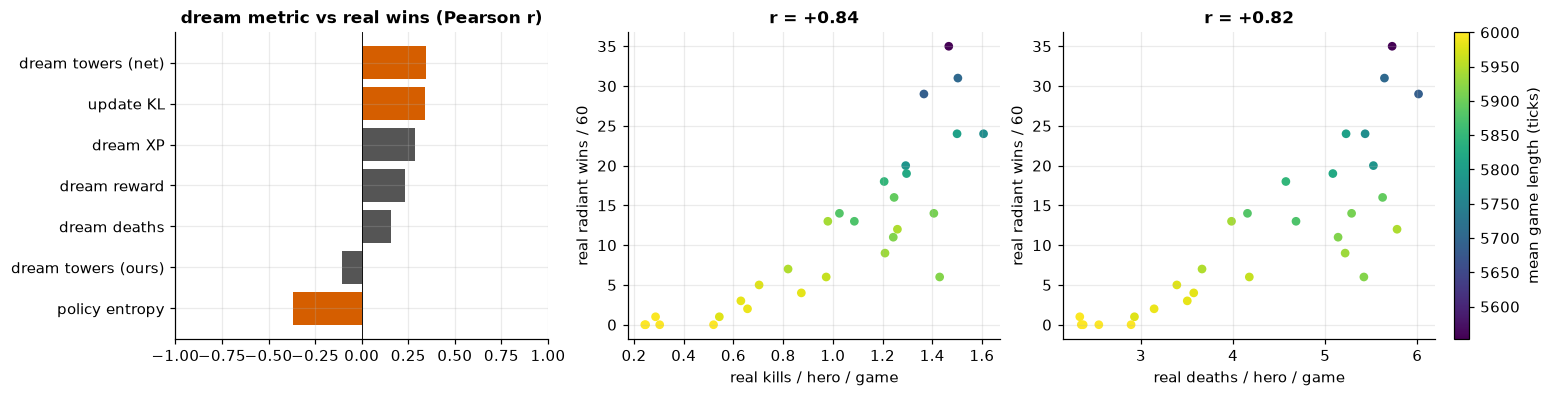

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
dm = [c for c in drift.columns if c.startswith("dream_")]
pretty = {"reward_per_1k": "dream reward", "xp_per_1k": "dream XP", "deaths_per_1k": "dream deaths", "ours_towers_per_episode": "dream towers (ours)",
          "opp_towers_per_episode": "dream towers (net)", "entropy": "policy entropy", "approx_kl": "update KL"}
corr = [(pretty.get(c[6:], c[6:]), np.corrcoef(drift[c], drift.real_wins)[0, 1]) for c in dm]
corr.sort(key=lambda t: t[1])
axs[0].barh([c for c, _ in corr], [v for _, v in corr], color=[C["bad"] if abs(v) > 0.3 else C["net"] for _, v in corr])
axs[0].axvline(0, color="black", lw=0.6); axs[0].set_xlim(-1, 1); axs[0].set_title("dream metric vs real wins (Pearson r)")
for ax, (m, lab) in zip(axs[1:], (("real_kills", "real kills / hero / game"), ("real_deaths", "real deaths / hero / game"))):
    sc = ax.scatter(drift[m], drift.real_wins, c=drift.real_ticks, cmap="viridis", s=22)
    ax.set_xlabel(lab); ax.set_ylabel("real radiant wins / 60")
    r = np.corrcoef(drift[m], drift.real_wins)[0, 1]; ax.set_title(f"r = {r:+.2f}")
fig.colorbar(sc, ax=axs[2], label="mean game length (ticks)")
save(fig, "fig4_drift_diagnosis")

## Figure 5. Offline (in-dream) training metrics

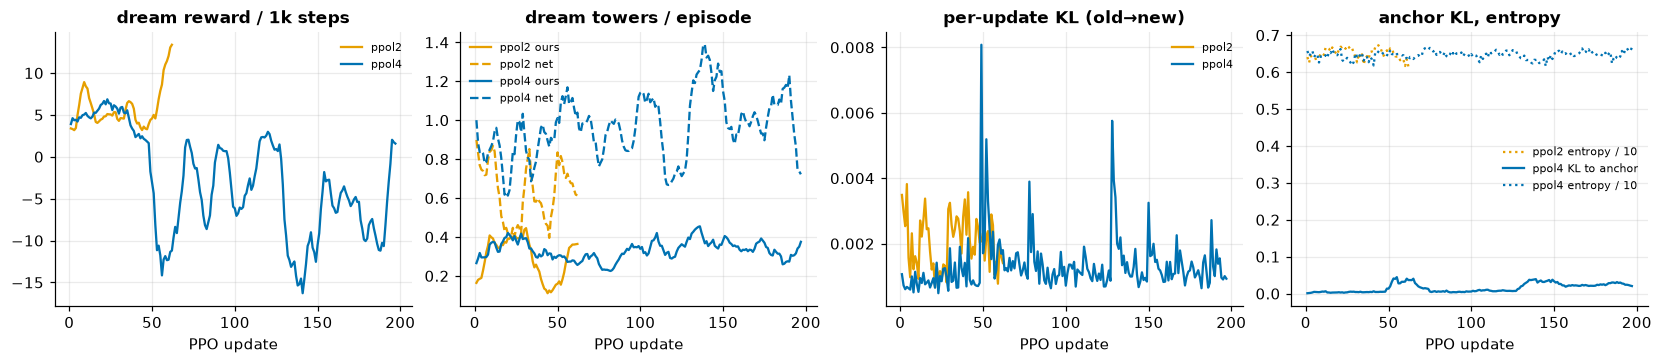

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.2))
for run, colr in (("ppol2", C["bad2"]), ("ppol4", C["ours"])):
    d = dream[dream.run == run].sort_values("update")
    axs[0].plot(d["update"], d.reward_per_1k.rolling(5, min_periods=1).mean(), color=colr, label=run)
    axs[1].plot(d["update"], d.ours_towers_per_episode.rolling(5, min_periods=1).mean(), color=colr, label=f"{run} ours")
    axs[1].plot(d["update"], d.opp_towers_per_episode.rolling(5, min_periods=1).mean(), color=colr, ls="--", label=f"{run} net")
    axs[2].plot(d["update"], d.approx_kl, color=colr, label=run)
    if d.kl_anchor.notna().any(): axs[3].plot(d["update"], d.kl_anchor, color=colr, label=f"{run} KL to anchor")
    axs[3].plot(d["update"], d.entropy / 10, color=colr, ls=":", label=f"{run} entropy / 10")
for ax, t in zip(axs, ("dream reward / 1k steps", "dream towers / episode", "per-update KL (old→new)", "anchor KL, entropy")):
    ax.set_title(t); ax.set_xlabel("PPO update"); ax.legend(fontsize=7)
save(fig, "fig5_dream_metrics")

## Figure 6. The world model during the loop: train, live (the policy's newest real games) and validation loss; tower fidelity
`wml` (red markers: followers lost to GPU memory from ~1,550, rank 0 alone, crashed at 3,675) and its restart `wml2`.
Tower fidelity: the 100-game tower evaluation on held-out corpus games at every checkpoint.

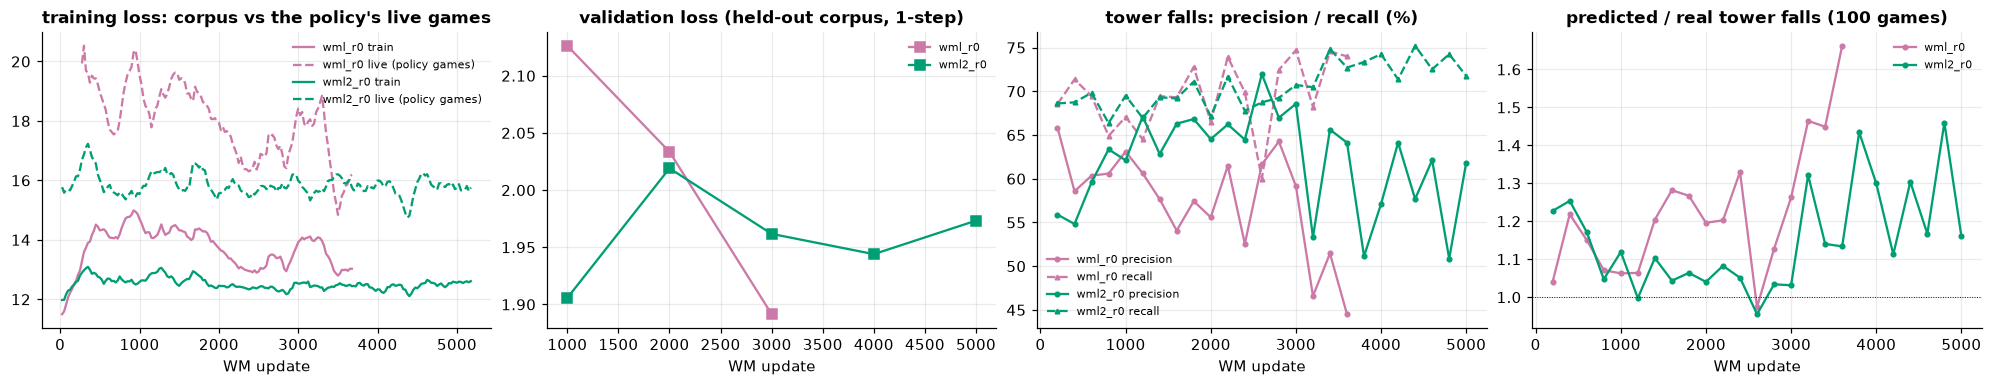

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.4))
for run, colr in (("wml_r0", C["e38"]), ("wml2_r0", C["dyna"])):
    d = wm[wm.run == run].sort_values("it")
    t = d.dropna(subset=["train_loss"])
    axs[0].plot(t.it, t.train_loss.rolling(8, min_periods=1).mean(), color=colr, label=f"{run} train")
    l = d.dropna(subset=["live_loss"])
    axs[0].plot(l.it, l.live_loss.rolling(8, min_periods=1).mean(), color=colr, ls="--", label=f"{run} live (policy games)")
    v = d.dropna(subset=["val_loss"])
    axs[1].plot(v.it, v.val_loss, "s-", color=colr, ms=6, label=f"{run}")
    tw = wmt[wmt.run == run].sort_values("it")
    axs[2].plot(tw.it, 100*tw.precision, "o-", color=colr, ms=3, label=f"{run} precision")
    axs[2].plot(tw.it, 100*tw.recall, "^--", color=colr, ms=3, label=f"{run} recall")
    axs[3].plot(tw.it, tw.pred / tw.real, "o-", color=colr, ms=3, label=run)
axs[0].set_title("training loss: corpus vs the policy's live games"); axs[0].set_xlabel("WM update"); axs[0].legend(fontsize=7)
axs[1].set_title("validation loss (held-out corpus, 1-step)"); axs[1].set_xlabel("WM update"); axs[1].legend(fontsize=7)
axs[2].set_title("tower falls: precision / recall (%)"); axs[2].set_xlabel("WM update"); axs[2].legend(fontsize=7)
axs[3].axhline(1, color="black", lw=0.6, ls=":"); axs[3].set_title("predicted / real tower falls (100 games)"); axs[3].set_xlabel("WM update"); axs[3].legend(fontsize=7)
save(fig, "fig6_world_model_training")

## Figure 7. Dyna metric: each world model on the *current* policy's real games (that no model trained on)
100 games the policy played after every checkpoint here was taken. Pre-Dyna (the E38 dream) never saw a policy game.

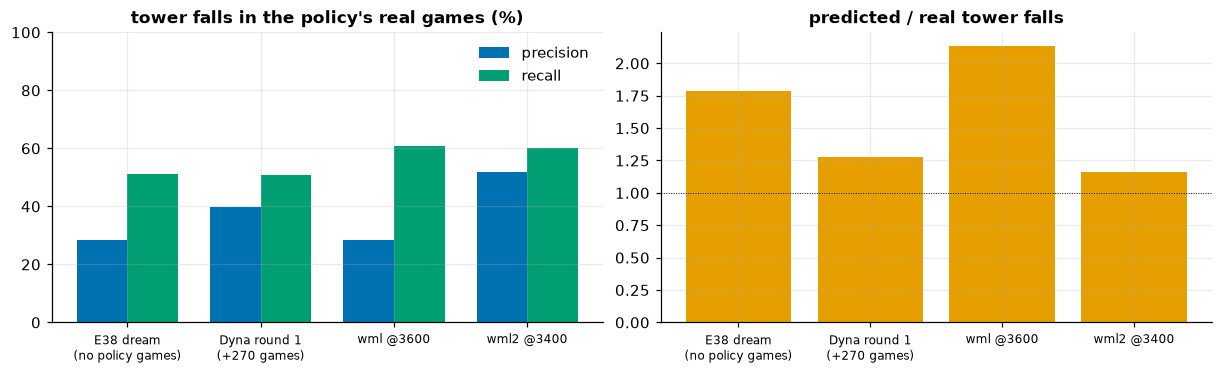

,games,precision,precision_ci,pred,real,recall,recall_ci,siege_ratio,windows,wm
0,100,0.285771,"[0.2608036447975033, 0.3173547796019092]",2502,1401,0.510350,"[0.4893332874512503, 0.5331913784616488]",0.636554,5265,fleet20e_at500
1,100,0.397982,"[0.364609332731242, 0.4365470801235501]",1784,1401,0.506781,"[0.4798249061363848, 0.5384615384615384]",0.583913,5265,wm_r1
2,100,0.517835,"[0.48909452708480144, 0.5491509761906701]",1626,1401,0.600999,"[0.577363493848206, 0.6261664389994024]",0.635790,5265,wml2_at3400
3,100,0.285475,"[0.2561454836426482, 0.315020312291761]",2988,1401,0.608851,"[0.5808640386303179, 0.6387343987133893]",0.655393,5265,wml_at3600


In [8]:
if not dyt.empty:
    order = [w for w in ("fleet20e_at500", "wm_r1", "wml_at3600", "wml2_at3400") if w in set(dyt.wm)]
    lab = {"fleet20e_at500": "E38 dream\n(no policy games)", "wm_r1": "Dyna round 1\n(+270 games)", "wml_at3600": "wml @3600",
           "wml2_at3400": "wml2 @3400"}
    d = dyt.set_index("wm").loc[order]
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.3))
    x = np.arange(len(order)); w = 0.38
    axs[0].bar(x - w/2, 100*d.precision, w, color=C["ours"], label="precision")
    axs[0].bar(x + w/2, 100*d.recall, w, color=C["dyna"], label="recall")
    axs[0].set_xticks(x, [lab[o] for o in order], fontsize=8); axs[0].set_ylim(0, 100); axs[0].legend(); axs[0].set_title("tower falls in the policy's real games (%)")
    axs[1].bar(x, d.pred / d.real, color=C["bad2"]); axs[1].axhline(1, color="black", lw=0.6, ls=":")
    axs[1].set_xticks(x, [lab[o] for o in order], fontsize=8); axs[1].set_title("predicted / real tower falls")
    save(fig, "fig7_dyna_metric")
    display(dyt)

## Figure 8. What contributed: ablations
Left: E39 ablation (from u71, frozen WM, no resets). Right: E40 frozen-world-model control, same recipe (death 0 + KL 0.3
to u71), the world model frozen at the pre-Dyna E38 dream vs the Dyna-trained one, two seeds each.

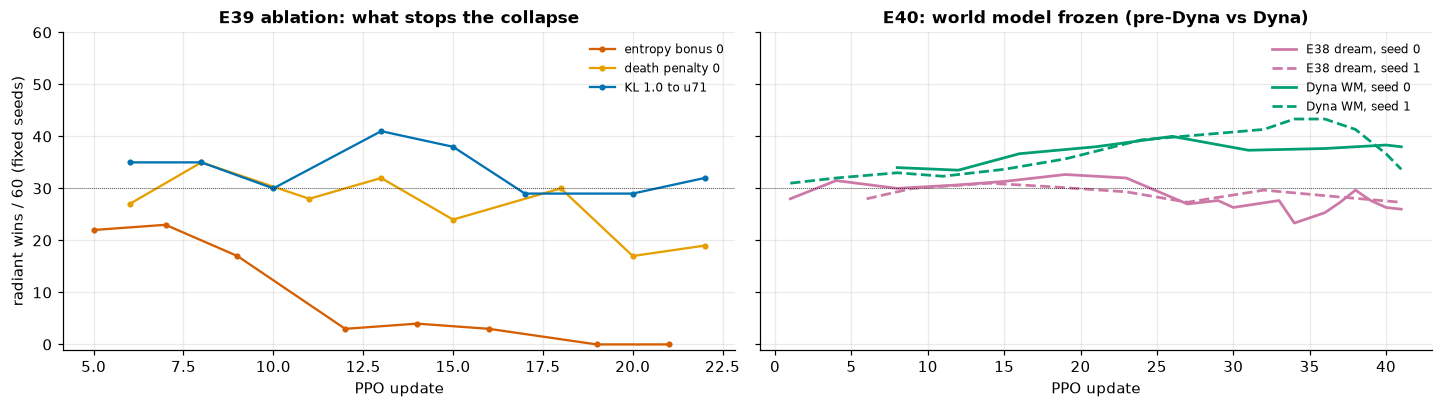

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for arm, colr, lab in (("abl_ent0", C["bad"], "entropy bonus 0"), ("abl_death0", C["bad2"], "death penalty 0"), ("abl_kl", C["ours"], "KL 1.0 to u71")):
    d = online[online.run == arm].sort_values("update")
    axs[0].plot(d["update"], d.radiant_wins, "o-", color=colr, label=lab, ms=3)
for arm, colr, ls, lab in (("fz_e38", C["e38"], "-", "E38 dream, seed 0"), ("fz_e38s1", C["e38"], "--", "E38 dream, seed 1"),
                           ("fz_dyna", C["dyna"], "-", "Dyna WM, seed 0"), ("fz_dynas1", C["dyna"], "--", "Dyna WM, seed 1")):
    d = online[online.run == arm].sort_values("update")
    if len(d): axs[1].plot(d["update"], d.radiant_wins.rolling(3, min_periods=1).mean(), ls, color=colr, label=lab, lw=1.8)
for ax, t in zip(axs, ("E39 ablation: what stops the collapse", "E40: world model frozen (pre-Dyna vs Dyna)")):
    ax.set_title(t); ax.set_xlabel("PPO update"); ax.legend(fontsize=8); ax.axhline(30, color="black", lw=0.5, ls=":")
axs[0].set_ylabel("radiant wins / 60 (fixed seeds)"); axs[0].set_ylim(-1, 60)
save(fig, "fig8_ablations")

## Figure 9. The contribution ladder: one change per rung, the same 300 holdout games per side

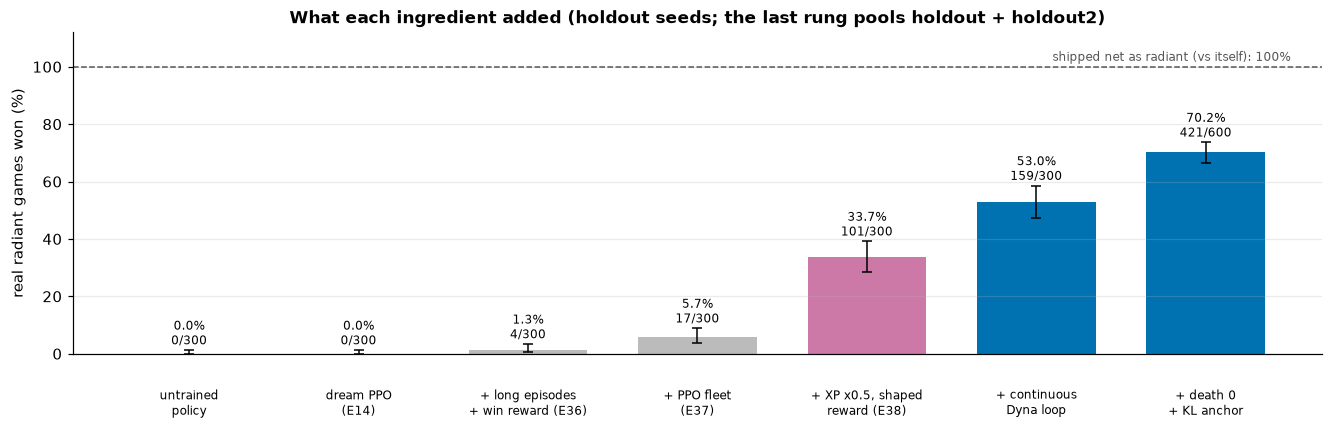

In [10]:
ladder = [("random", "untrained\npolicy"), ("e14_armC", "dream PPO\n(E14)"), ("e36_J_envs128_4x_s2", "+ long episodes\n+ win reward (E36)"),
          ("e37_pf1_u7", "+ PPO fleet\n(E37)"), ("e38_u0017", "+ XP x0.5, shaped\nreward (E38)"), ("ppol_u71", "+ continuous\nDyna loop"),
          ("ppol4_u69", "+ death 0\n+ KL anchor")]
fig, ax = plt.subplots(figsize=(12, 3.8))
ref = hold.get("shipped_net")
for i, (l, name) in enumerate(ladder):
    r = hold.get(l)
    if r is None: continue
    k, n = r["radiant_wins"], r["radiant_games"]
    h2 = {x["label"]: x for x in ev if x["set"] == "holdout2"}.get(l)
    if h2: k, n = k + h2["radiant_wins"], n + h2["radiant_games"]
    p, lo, hi = wilson(k, n)
    ax.bar(i, 100*p, color=C["ours"] if i >= 5 else C["e38"] if i == 4 else C["rand"], width=0.7)
    ax.errorbar(i, 100*p, yerr=[[100*(p-lo)], [100*(hi-p)]], color="black", capsize=3, lw=1)
    ax.text(i, 100*hi + 2, f"{100*p:.1f}%\n{k}/{n}", ha="center", fontsize=8)
    ax.text(i, -12, name, ha="center", va="top", fontsize=8)
if ref:
    ax.axhline(100*ref["radiant_rate"] if "radiant_rate" in ref else 100*ref["radiant_wins"]/ref["radiant_games"], color=C["net"], ls="--", lw=1)
    ax.text(len(ladder) - 0.5, 101, "shipped net as radiant (vs itself): 100%", ha="right", va="bottom", fontsize=8, color=C["net"])
ax.set_xticks([]); ax.set_ylim(0, 112); ax.set_ylabel("real radiant games won (%)")
ax.set_title("What each ingredient added (holdout seeds; the last rung pools holdout + holdout2)")
save(fig, "fig9_contribution_ladder")

## Figure 10-11. How the policy plays the real game, against the shipped net's own radiant play
20 holdout games each, as radiant. `scripts/moba/behaviour_analysis.py`.

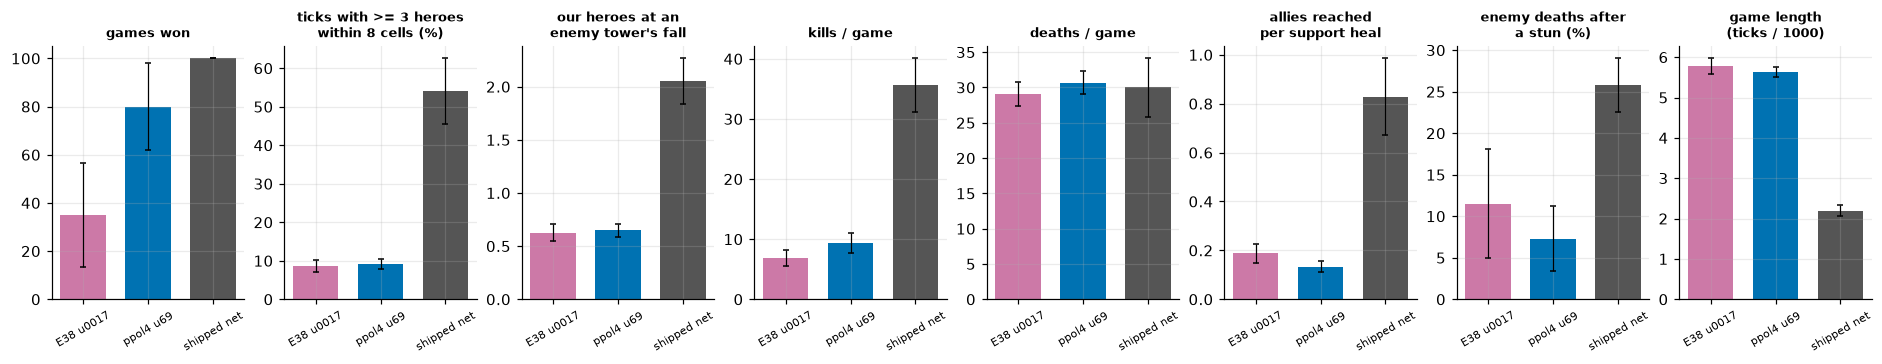

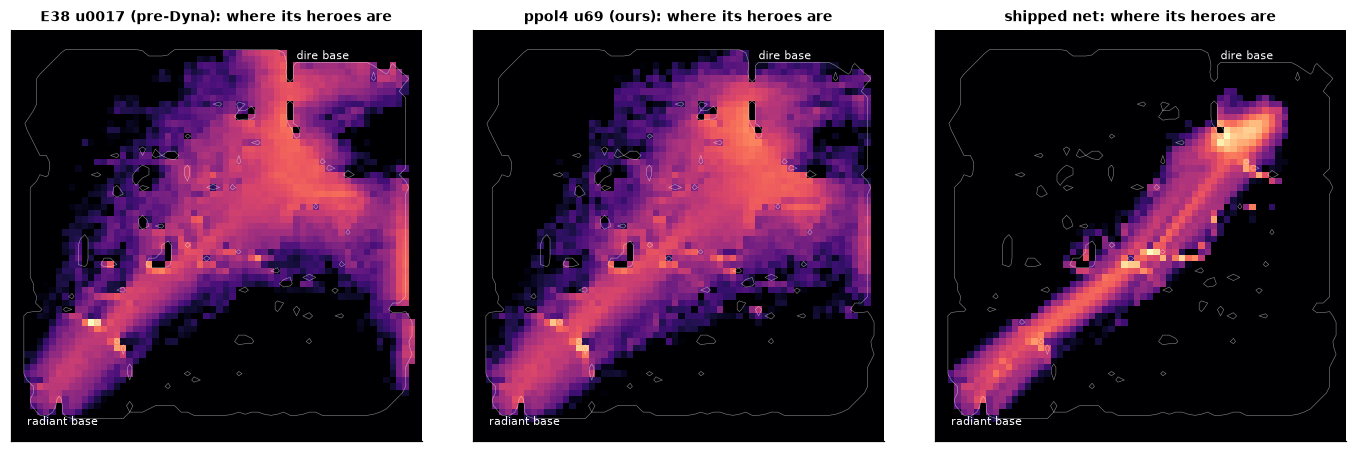

,won,grouped,heroes_at_fall,kills,deaths,heal_allies_mean,stun_before_kill,ticks,spread,focus_hero,focus_tower,enemy_towers,support_heals
label,,,,,,,,,,,,,
e38_u0017,0.35,0.09,0.63,6.85,29.1,0.19,0.12,5778.15,42.54,0.72,0.50,9.30,85.00
ppol4_u69,0.80,0.09,0.65,9.35,30.7,0.13,0.07,5633.80,39.67,0.85,0.83,9.95,83.55
shipped_net,1.00,0.54,2.05,35.65,30.0,0.83,0.26,2200.20,31.67,0.82,0.86,6.20,35.00


In [11]:
B = pd.read_json(P / "behaviour.jsonl", lines=True) if (P / "behaviour.jsonl").exists() else pd.DataFrame()
if not B.empty:
    labs = [l for l in ("e38_u0017", "ppol4_u69", "shipped_net") if l in set(B.label)]
    nice = {"e38_u0017": "E38 u0017 (pre-Dyna)", "ppol4_u69": "ppol4 u69 (ours)", "shipped_net": "shipped net"}
    colr = {"e38_u0017": C["e38"], "ppol4_u69": C["ours"], "shipped_net": C["net"]}
    mets = [("won", "games won", 100), ("grouped", "ticks with >= 3 heroes\nwithin 8 cells (%)", 100),
            ("heroes_at_fall", "our heroes at an\nenemy tower's fall", 1), ("kills", "kills / game", 1), ("deaths", "deaths / game", 1),
            ("heal_allies_mean", "allies reached\nper support heal", 1), ("stun_before_kill", "enemy deaths after\na stun (%)", 100),
            ("ticks", "game length\n(ticks / 1000)", 1/1000)]
    fig, axs = plt.subplots(1, len(mets), figsize=(17, 3.2))
    for ax, (m, t, sc) in zip(axs, mets):
        for i, l in enumerate(labs):
            v = B[B.label == l][m].dropna() * sc
            ax.bar(i, v.mean(), color=colr[l], width=0.7)
            ax.errorbar(i, v.mean(), yerr=1.96 * v.std(ddof=1) / max(np.sqrt(len(v)), 1), color="black", capsize=2, lw=0.8)
        ax.set_xticks(range(len(labs)), [nice[l].split(" (")[0] for l in labs], rotation=30, fontsize=7); ax.set_title(t, fontsize=8.5)
    save(fig, "fig10_behaviour")
    maps = np.load(P / "behaviour_maps.npz")
    import sys; sys.path.insert(0, str(ROOT))
    from mobawm.wm.data import load_walls
    W128 = np.asarray(load_walls(), float).reshape(128, 128)
    WALLS64 = W128.reshape(64, 2, 64, 2).mean((1, 3))
    mlabs = [l for l in labs if l in maps.files]
    fig, axs = plt.subplots(1, len(mlabs), figsize=(4.2 * len(mlabs), 4))
    for ax, l in zip(np.atleast_1d(axs), mlabs):
        ax.imshow(np.log10(maps[l] + 1e-6), cmap="magma", origin="upper", vmin=-5, vmax=-1.5)
        ax.contour(WALLS64, levels=[0.5], colors="white", linewidths=0.4, alpha=0.5)          # the map's walls
        ax.text(2, 61, "radiant base", color="white", fontsize=7); ax.text(44, 4, "dire base", color="white", fontsize=7)
        ax.set_title(f"{nice[l]}: where its heroes are", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    save(fig, "fig11_occupancy")
    display(B.groupby("label")[[m for m, _, _ in mets] + ["spread", "focus_hero", "focus_tower", "enemy_towers", "support_heals"]].mean().round(2))

## Figure 12. The debugger, in batch: open-loop divergence on the policy's own real games
Hero position and HP error vs the real game at 16-200 ticks of open loop (lower is better), per world-model version;
dotted: persistence (holding the start state). `scripts/moba/debugger_eval.py`.

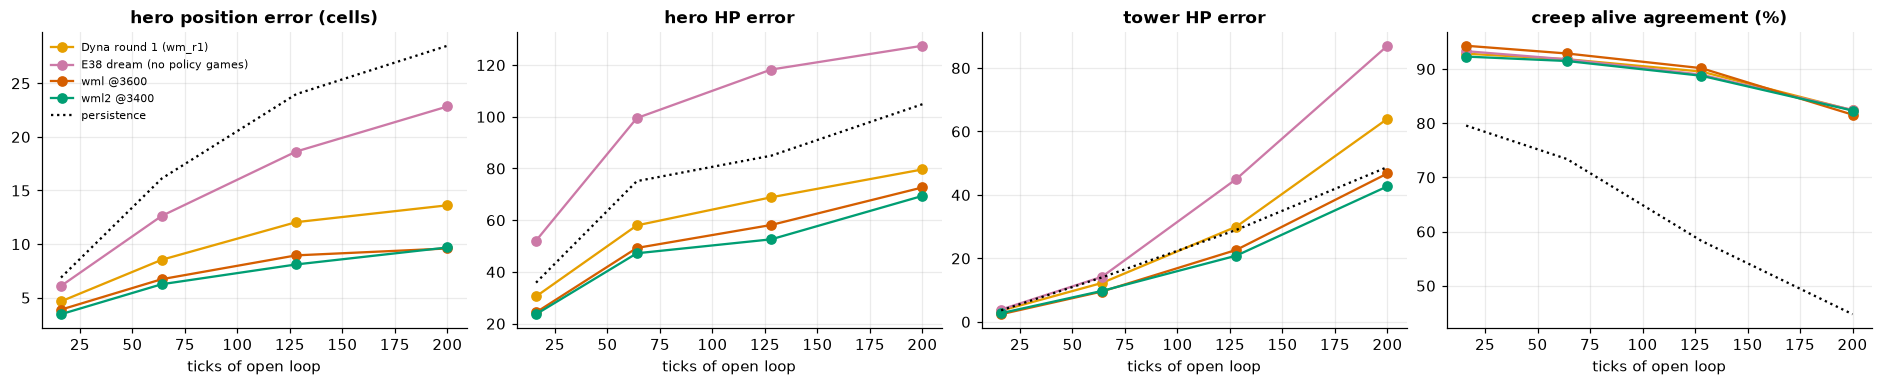

model_hero pos L1 (cells)  \
model                       step                              
Dyna round 1 (wm_r1)        16                         4.66   
                            64                         8.54   
                            128                       12.05   
                            200                       13.62   
E38 dream (no policy games) 16                         6.10   
                            64                        12.63   
                            128                       18.63   
                            200                       22.83   
wml @3600                   16                         3.89   
                            64                         6.73   
                            128                        8.95   
                            200                        9.59   
wml2 @3400                  16                         3.46   
                            64                         6.26   
                            128                        8.10   
                            200                        9.69   

                                  model_hero hp MAE  \
model                       step                      
Dyna round 1 (wm_r1)        16                30.54   
                            64                58.00   
                            128               68.87   
                            200               79.63   
E38 dream (no policy games) 16                52.11   
                            64                99.50   
                            128              118.27   
                            200              127.46   
wml @3600                   16                24.36   
                            64                49.28   
                            128               58.16   
                            200               72.67   
wml2 @3400                  16                23.66   
                            64                47.22   
                            128               52.61   
                            200               69.40   

                                  model_creep alive agree %  \
model                       step                              
Dyna round 1 (wm_r1)        16                        92.83   
                            64                        91.81   
                            128                       89.53   
                            200                       82.39   
E38 dream (no policy games) 16                        93.29   
                            64                        91.79   
                            128                       88.96   
                            200                       82.44   
wml @3600                   16                        94.29   
                            64                        92.87   
                            128                       90.16   
                            200                       81.57   
wml2 @3400                  16                        92.29   
                            64                        91.48   
                            128                       88.76   
                            200                       82.33   

                                  model_tower hp MAE  
model                       step                      
Dyna round 1 (wm_r1)        16                  3.55  
                            64                 12.26  
                            128                30.00  
                            200                64.02  
E38 dream (no policy games) 16                  3.89  
                            64                 14.20  
                            128                45.02  
                            200                87.02  
wml @3600                   16                  2.41  
                            64                  9.56  
                            128                22.68  
                            200                46.79  
wml

In [12]:
DE = read("debugger_eval.csv")
if not DE.empty:
    mets = [("hero pos L1 (cells)", "hero position error (cells)"), ("hero hp MAE", "hero HP error"),
            ("tower hp MAE", "tower HP error"), ("creep alive agree %", "creep alive agreement (%)")]
    mc = {"E38 dream (no policy games)": C["e38"], "Dyna round 1 (wm_r1)": C["bad2"], "wml @3600": C["bad"], "wml2 @3400": C["dyna"]}
    fig, axs = plt.subplots(1, 4, figsize=(17, 3.4))
    for ax, (m, t) in zip(axs, mets):
        for mod, g in DE.groupby("model"):
            k = g.groupby("step")[f"model_{m}"].mean()
            ax.plot(k.index, k.values, "o-", color=mc.get(mod, "k"), label=mod)
        pk = DE.groupby("step")[f"persist_{m}"].mean(); ax.plot(pk.index, pk.values, ":", color="black", label="persistence")
        ax.set_title(t); ax.set_xlabel("ticks of open loop")
    axs[0].legend(fontsize=7)
    save(fig, "fig12_debugger_divergence")
    display(DE.groupby(["model", "step"])[[c for c in DE.columns if c.startswith("model_")]].mean().round(2))

## Figure 13. Mechanic by mechanic: does the dream fire abilities, heal, blink, stun, kill, when the real game does?
Event-level precision and recall (same hero, +-4 ticks) over 64-tick open-loop windows on the policy's own real games.
`scripts/moba/wm_mechanics_eval.py`.

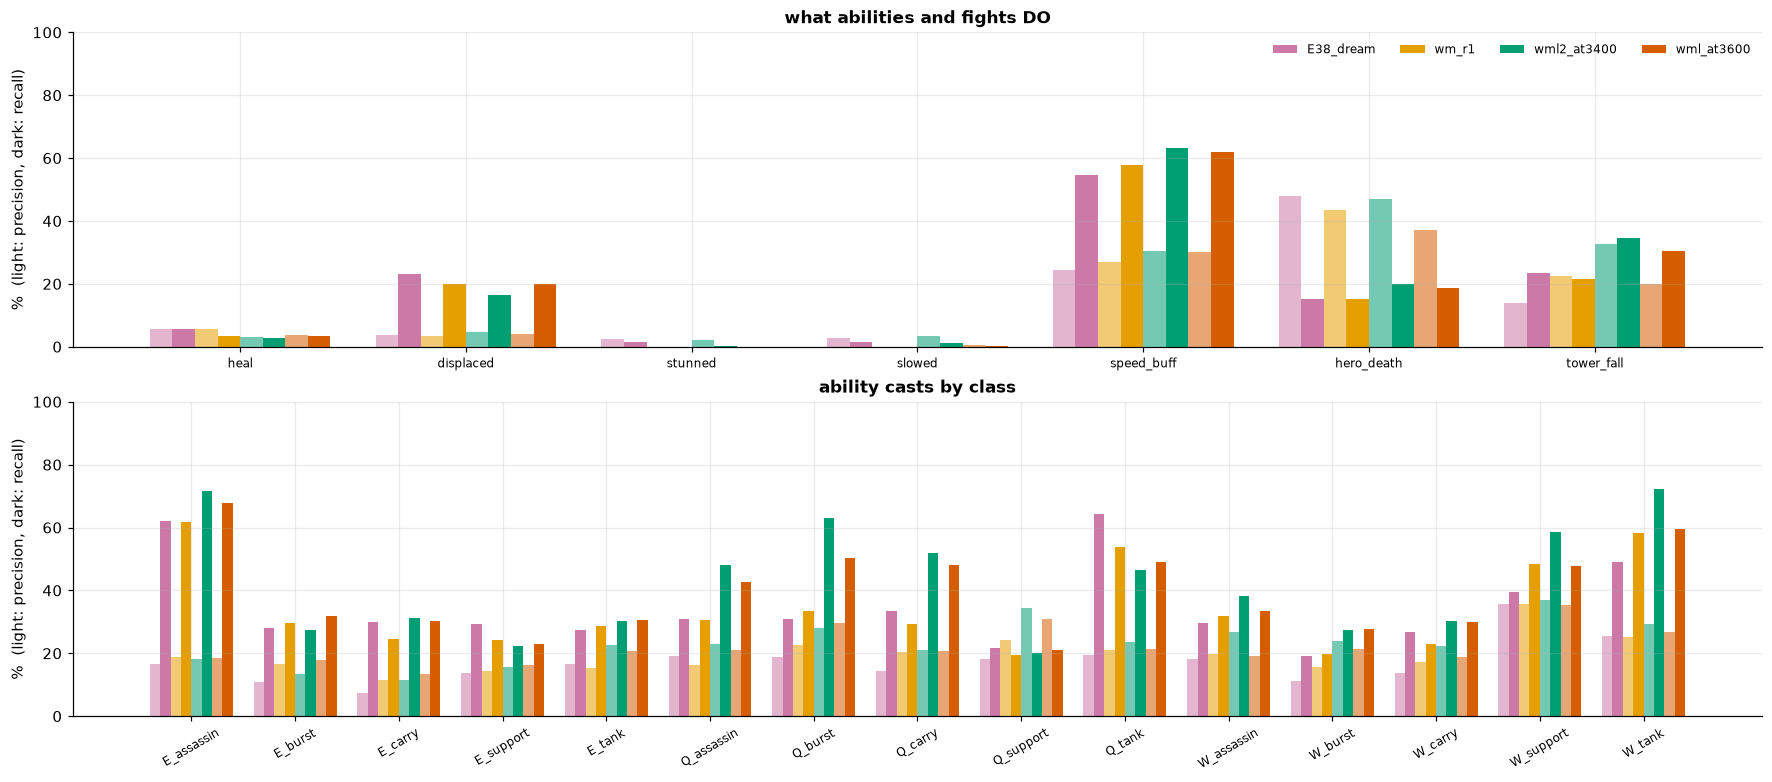

ratio                             
model           E38_dream wm_r1 wml2_at3400 wml_at3600
kind                                                  
cast_E_assassin      3.74  3.27        3.95       3.65
cast_E_burst         2.57  1.79        2.05       1.79
cast_E_carry         3.98  2.14        2.68       2.28
cast_E_support       2.15  1.67        1.44       1.40
cast_E_tank          1.64  1.86        1.34       1.48
cast_Q_assassin      1.62  1.88        2.09       2.04
cast_Q_burst         1.64  1.48        2.24       1.70
cast_Q_carry         2.34  1.44        2.48       2.31
cast_Q_support       1.20  0.80        0.59       0.68
cast_Q_tank          3.29  2.57        1.98       2.29
cast_W_assassin      1.64  1.61        1.42       1.77
cast_W_burst         1.70  1.26        1.15       1.28
cast_W_carry         1.96  1.33        1.36       1.59
cast_W_support       1.11  1.36        1.59       1.35
cast_W_tank          1.92  2.30        2.46       2.22
displaced            6.16  5.69        3.55       5.08
heal                 0.96  0.62        0.91       0.90
hero_death           0.32  0.35        0.42       0.50
slowed               0.52  0.27        0.34       0.55
speed_buff           2.25  2.14        2.08       2.04
stunned              0.67  0.09        0.17       0.16
tower_fall           1.68  0.96        1.06       1.52

In [13]:
WM = read("wm_mechanics.csv")
if not WM.empty:
    kinds = ["heal", "displaced", "stunned", "slowed", "speed_buff", "hero_death", "tower_fall"]
    casts = sorted(k for k in set(WM.kind) if k.startswith("cast_"))
    fig, axs = plt.subplots(2, 1, figsize=(16, 7))
    for ax, ks, t in ((axs[0], kinds, "what abilities and fights DO"), (axs[1], casts, "ability casts by class")):
        mods = list(dict.fromkeys(WM.model)); w = 0.8 / (2 * len(mods)); x = np.arange(len(ks))
        mc = {"E38_dream": C["e38"], "wm_r1": C["bad2"], "wml_at3600": C["bad"], "wml2_at3400": C["dyna"]}
        for j, mod in enumerate(mods):
            d = WM[WM.model == mod].set_index("kind").reindex(ks)
            ax.bar(x + (2*j) * w - 0.4 + w/2, 100*d.precision, w, color=mc.get(mod, "k"), alpha=0.55)
            ax.bar(x + (2*j+1) * w - 0.4 + w/2, 100*d.recall, w, color=mc.get(mod, "k"), label=mod)
        ax.set_xticks(x, [k.replace("cast_", "") for k in ks], rotation=30 if ax is axs[1] else 0, fontsize=8)
        ax.set_ylim(0, 100); ax.set_ylabel("%  (light: precision, dark: recall)"); ax.set_title(t)
    axs[0].legend(fontsize=8, ncol=4)
    save(fig, "fig13_wm_mechanics")
    display(WM.pivot(index="kind", columns="model", values=["ratio"]).round(2))

## Numbers quoted in the paper

In [14]:
print(json.dumps({k: N[k] for k in ("headline", "deltas_vs_headline", "collector_radiant", "collector_dire", "anchor", "resets") if k in N}, indent=1, default=str))

{
 "headline": {
  "policy": "ppol4_u69",
  "set": "holdout",
  "radiant_wins": 213,
  "radiant_games": 300,
  "radiant_rate": 0.71,
  "radiant_ci95": [
   0.6562534723961281,
   0.7584362870048228
  ],
  "dire_wins": 0,
  "dire_games": 300,
  "dire_ci95": [
   0.0,
   0.012643429997735661
  ],
  "pooled_untouched": {
   "radiant_wins": 421,
   "radiant_games": 600,
   "rate": 0.7016666666666667,
   "ci95": [
    0.6638680212177496,
    0.7368993323398721
   ]
  }
 },
 "deltas_vs_headline": {
  "e38_u0017": {
   "diff": 0.3733333333333333,
   "ci95": [
    0.29625928148331426,
    0.4437501628037733
   ],
   "other_rate": 0.33666666666666667
  },
  "ppol_u71": {
   "diff": 0.17999999999999994,
   "ci95": [
    0.10256692379137546,
    0.2544205223361686
   ],
   "other_rate": 0.53
  },
  "ppol4_u10": {
   "diff": 0.15333333333333332,
   "ci95": [
    0.07632732487281656,
    0.22781425126998217
   ],
   "other_rate": 0.5566666666666666
  },
  "ppol4_u49": {
   "diff": 0.033333333333333